# Task 2 (Implement Both Models From Scratch (NumPy))

Using the data prepared in Task 1 (Glucose and BMI, stratified 80/20 split, train-only imputation and scaling), we implement:

1. **Perceptron** — weighted sum, step activation, mistake-driven updates
2. **Logistic Regression** — sigmoid, log loss, batch gradient descent

For both we include bias updates and a stopping rule / fixed iteration count, print the learned coefficients, the first five test predictions, and (logistic only) the first five predicted positive-class probabilities, and plot the logistic loss against epochs.

## 0. Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Load the Prepared Data from Task 1

If `prepared_diabetes_data.npz` (saved by Task 1) is not found, the cell below rebuilds exactly the same data
(same split, same training-only median imputation and scaling), so this notebook also runs on its own.

In [2]:
if os.path.exists("prepared_diabetes_data.npz"):
    d = np.load("prepared_diabetes_data.npz", allow_pickle=True)
    X_train, X_test = d["X_train"], d["X_test"]
    y_train, y_test = d["y_train"], d["y_test"]
    FEATURES = [str(f) for f in d["features"]]
    print("Loaded prepared_diabetes_data.npz")
else:
    from sklearn.model_selection import train_test_split
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler

    COLS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
    if os.path.exists("diabetes.csv"):
        df = pd.read_csv("diabetes.csv")
    else:
        url = ("https://raw.githubusercontent.com/jbrownlee/Datasets/master/"
               "pima-indians-diabetes.data.csv")
        df = pd.read_csv(url, header=None, names=COLS)

    FEATURES = ["Glucose", "BMI"]
    df[["Glucose", "BMI"]] = df[["Glucose", "BMI"]].replace(0, np.nan)
    Xr, yr = df[FEATURES], df["Outcome"]
    Xtr, Xte, ytr, yte = train_test_split(Xr, yr, test_size=0.20, stratify=yr,
                                          random_state=RANDOM_STATE)
    imp = SimpleImputer(strategy="median").fit(Xtr)
    sc = StandardScaler().fit(imp.transform(Xtr))
    X_train = sc.transform(imp.transform(Xtr)); X_test = sc.transform(imp.transform(Xte))
    y_train = ytr.to_numpy().astype(int);       y_test = yte.to_numpy().astype(int)
    print("Rebuilt the Task 1 data pipeline")

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Features:", FEATURES)
print("Positive rate  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Loaded prepared_diabetes_data.npz
X_train: (614, 2) | X_test: (154, 2)
Features: ['Glucose', 'BMI']
Positive rate  train: 0.349 | test: 0.351


## 2. Perceptron From Scratch

**Model:** $z = \mathbf{w}\cdot\mathbf{x} + b$, prediction $\hat y = 1$ if $z \ge 0$ else $0$ (step activation).

**Learning rule (mistake-driven):** for each training sample

- $error = y - \hat y$
- $\mathbf{w} \leftarrow \mathbf{w} + \eta \cdot error \cdot \mathbf{x}$
- $b \leftarrow b + \eta \cdot error$

If the prediction is correct, `error = 0` and nothing changes.

**Stopping rule:** stop early if an epoch has zero mistakes (only possible when the data is linearly separable);
otherwise stop at `max_epochs`. Our data is **not** separable, so the fixed epoch limit will be what ends training.
Samples are visited in a shuffled order each epoch (seeded for reproducibility).

In [3]:
class PerceptronScratch:
    def __init__(self, lr=0.1, max_epochs=100, random_state=42):
        self.lr = lr
        self.max_epochs = max_epochs
        self.random_state = random_state

    @staticmethod
    def step(z):
        return (np.asarray(z) >= 0).astype(int)

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        n, m = X.shape
        self.w = np.zeros(m)
        self.b = 0.0
        self.errors_per_epoch = []
        self.converged = False

        for epoch in range(self.max_epochs):
            errors = 0
            for i in rng.permutation(n):
                pred = int(self.step(X[i] @ self.w + self.b))
                error = y[i] - pred
                if error != 0:                          # update only on mistakes
                    self.w += self.lr * error * X[i]
                    self.b += self.lr * error
                    errors += 1
            self.errors_per_epoch.append(errors)
            if errors == 0:                             # stopping rule
                self.converged = True
                break
        self.n_epochs = len(self.errors_per_epoch)
        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return self.step(self.decision_function(X))

In [4]:
perc = PerceptronScratch(lr=0.1, max_epochs=100, random_state=RANDOM_STATE).fit(X_train, y_train)

print("Converged (zero-mistake epoch)?:", perc.converged)
print("Epochs run                     :", perc.n_epochs)
print("Learned weights (w_%s, w_%s)   :" % tuple(FEATURES), perc.w.round(4))
print("Learned bias                   :", round(perc.b, 4))
print("Mistakes in last epoch         :", perc.errors_per_epoch[-1])

perc_test_pred = perc.predict(X_test)
print("\nFirst 5 test predictions (Perceptron):", perc_test_pred[:5].tolist())
print("First 5 true test labels             :", y_test[:5].tolist())

Converged (zero-mistake epoch)?: False
Epochs run                     : 100
Learned weights (w_Glucose, w_BMI)   : [0.2557 0.1914]
Learned bias                   : -0.1
Mistakes in last epoch         : 176

First 5 test predictions (Perceptron): [1, 0, 0, 0, 0]
First 5 true test labels             : [0, 0, 0, 1, 0]


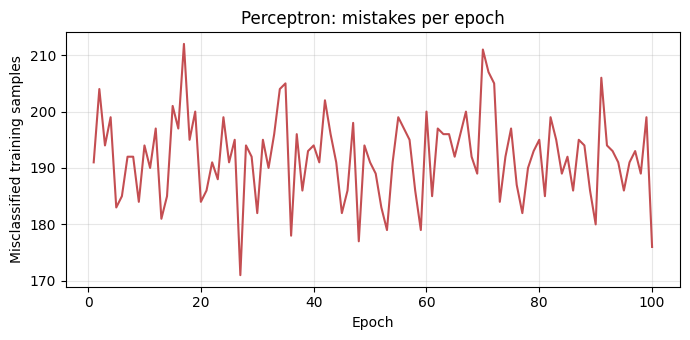

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, perc.n_epochs + 1), perc.errors_per_epoch, color="#C44E52")
ax.set_xlabel("Epoch"); ax.set_ylabel("Misclassified training samples")
ax.set_title("Perceptron: mistakes per epoch")
ax.grid(alpha=.3); plt.tight_layout(); plt.show()

**Reading the plot:** the number of mistakes does not reach zero, it fluctuates. This is the expected behaviour when classes overlap:
the perceptron convergence theorem only guarantees convergence for linearly separable data. Because the final weights come from
the last few updates, they are somewhat "noisy" and depend on the sample order and learning rate.

### 2.1 Effect of the learning rate (Perceptron)

In [6]:
rows = []
for lr in [0.001, 0.01, 0.1, 1.0]:
    p = PerceptronScratch(lr=lr, max_epochs=100, random_state=RANDOM_STATE).fit(X_train, y_train)
    rows.append({"lr": lr,
                 "epochs run": p.n_epochs,
                 "last-epoch mistakes": p.errors_per_epoch[-1],
                 "min mistakes in any epoch": min(p.errors_per_epoch),
                 "train acc": round((p.predict(X_train) == y_train).mean(), 4),
                 "w": p.w.round(3).tolist(), "b": round(p.b, 3)})
pd.DataFrame(rows)

,lr,epochs run,last-epoch mistakes,min mistakes in any epoch,train acc,w,b
0,0.001,100,176,171,0.7606,"[0.003, 0.002]",-0.001
1,0.010,100,176,171,0.7606,"[0.026, 0.019]",-0.010
2,0.100,100,176,171,0.7606,"[0.256, 0.191]",-0.100
3,1.000,100,176,171,0.7606,"[2.557, 1.914]",-1.000


Because we start from zero weights and the step function only looks at the **sign** of $z$, multiplying every update by the same $\eta$
just rescales $(\mathbf{w}, b)$ and leaves the decision boundary exactly the same: the table shows identical mistake counts and accuracy for every $\eta$, while $\mathbf{w}$ and $b$ scale in proportion to $\eta$.
This is different from Logistic Regression, where the learning rate really affects the speed and stability of gradient descent.

## 3. Logistic Regression From Scratch (Batch Gradient Descent)

**Model:** $z = \mathbf{w}\cdot\mathbf{x} + b$, $\;p = \sigma(z) = \dfrac{1}{1+e^{-z}}$, predict class 1 if $p \ge 0.5$.

**Loss (binary cross-entropy / log loss):**
$$L = -\frac1m\sum_{i=1}^{m}\big[\,y_i\log p_i + (1-y_i)\log(1-p_i)\,\big]$$

**Gradients (all $m$ samples at once = batch):**
$$d\mathbf{w} = \frac{1}{m}X^\top(\mathbf{p}-\mathbf{y}), \qquad db = \text{mean}(\mathbf{p}-\mathbf{y})$$

**Update:** $\mathbf{w} \leftarrow \mathbf{w} - \eta\, d\mathbf{w}$, $\;b \leftarrow b - \eta\, db$.

**Stopping rule:** stop when the loss improvement between epochs is smaller than `tol`, or at `max_epochs`.
Probabilities are clipped to $[10^{-12}, 1-10^{-12}]$ inside the loss so that $\log(0)$ never occurs.
No regularization is used (scikit-learn applies L2 by default, which is one reason coefficients differ later in Task 3).

In [7]:
def sigmoid(z):
    z = np.clip(z, -500, 500)                     # avoid overflow in exp
    return 1.0 / (1.0 + np.exp(-z))

def log_loss_manual(y_true, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

class LogisticRegressionScratch:
    def __init__(self, lr=0.1, max_epochs=5000, tol=1e-9):
        self.lr = lr
        self.max_epochs = max_epochs
        self.tol = tol

    def fit(self, X, y):
        n, m = X.shape
        self.w = np.zeros(m)
        self.b = 0.0
        self.loss_history = []

        for epoch in range(self.max_epochs):
            p = sigmoid(X @ self.w + self.b)
            self.loss_history.append(log_loss_manual(y, p))

            dw = X.T @ (p - y) / n
            db = np.mean(p - y)
            self.w -= self.lr * dw
            self.b -= self.lr * db

            if epoch > 0 and abs(self.loss_history[-2] - self.loss_history[-1]) < self.tol:
                break                                   # stopping rule
        self.n_epochs = len(self.loss_history)
        return self

    def predict_proba(self, X):
        return sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [8]:
logit = LogisticRegressionScratch(lr=0.1, max_epochs=5000, tol=1e-9).fit(X_train, y_train)

print("Epochs run                     :", logit.n_epochs)
print("Final training log loss        :", round(logit.loss_history[-1], 5))
print("Learned weights (w_%s, w_%s)   :" % tuple(FEATURES), logit.w.round(4))
print("Learned bias                   :", round(logit.b, 4))

logit_test_proba = logit.predict_proba(X_test)
logit_test_pred  = logit.predict(X_test)
print("\nFirst 5 test predictions (Logistic)           :", logit_test_pred[:5].tolist())
print("First 5 predicted P(class = 1) (Logistic)     :", logit_test_proba[:5].round(4).tolist())
print("First 5 true test labels                      :", y_test[:5].tolist())

Epochs run                     : 693
Final training log loss        : 0.47274
Learned weights (w_Glucose, w_BMI)   : [1.2489 0.6659]
Learned bias                   : -0.8375

First 5 test predictions (Logistic)           : [1, 0, 0, 0, 0]
First 5 predicted P(class = 1) (Logistic)     : [0.5559, 0.0587, 0.3807, 0.1611, 0.0558]
First 5 true test labels                      : [0, 0, 0, 1, 0]


### 3.1 Loss against epochs

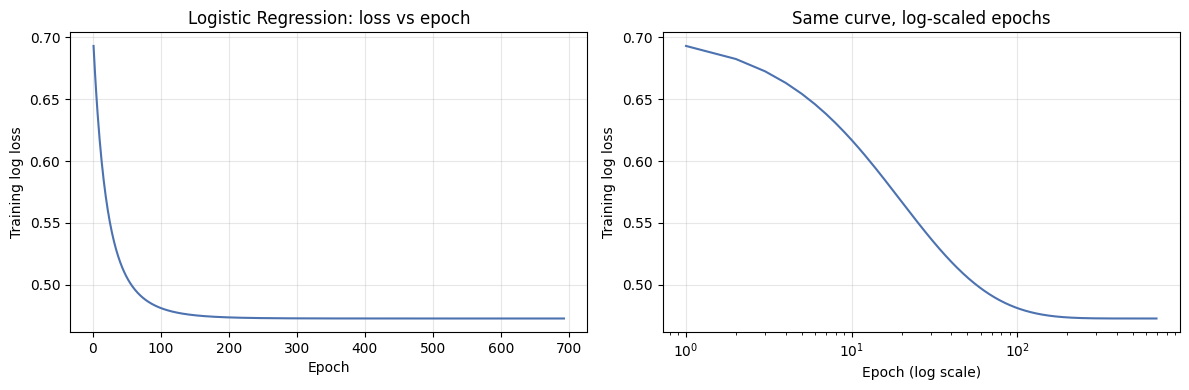

Loss at epoch 1   : 0.6931 (= ln 2 = 0.6931 for w=0)
Loss at last epoch: 0.4727
Monotonically non-increasing?: True


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, logit.n_epochs + 1), logit.loss_history, color="#4C72B0")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Training log loss")
axes[0].set_title("Logistic Regression: loss vs epoch")
axes[0].grid(alpha=.3)

axes[1].plot(range(1, logit.n_epochs + 1), logit.loss_history, color="#4C72B0")
axes[1].set_xscale("log")
axes[1].set_xlabel("Epoch (log scale)"); axes[1].set_ylabel("Training log loss")
axes[1].set_title("Same curve, log-scaled epochs")
axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Loss at epoch 1   :", round(logit.loss_history[0], 4), "(= ln 2 = %.4f for w=0)" % np.log(2))
print("Loss at last epoch:", round(logit.loss_history[-1], 4))
print("Monotonically non-increasing?:", bool(np.all(np.diff(logit.loss_history) <= 1e-12)))

The loss starts at $\ln 2 \approx 0.693$ (all probabilities are 0.5 with zero weights) and decreases smoothly until the improvement
falls below the tolerance. A smooth, monotone decrease is the sign of a well-chosen learning rate and of standardized features.
Log loss is convex, so batch gradient descent heads to the global minimum.

### 3.2 Effect of the learning rate (Logistic Regression)

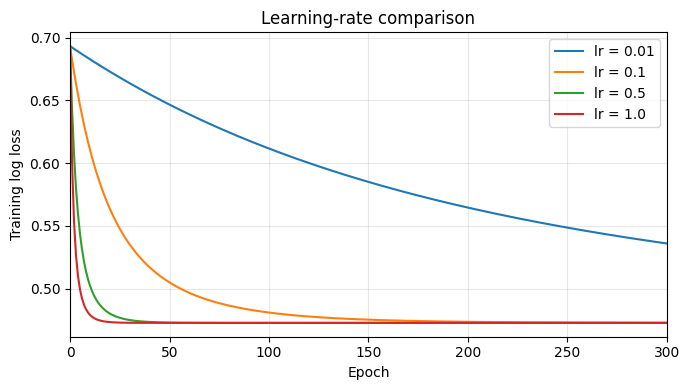

,lr,loss @ epoch 100,final loss (2000 ep)
0,0.01,0.61222,0.47364
1,0.10,0.48118,0.47274
2,0.50,0.47275,0.47274
3,1.00,0.47274,0.47274


In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
rows = []
for lr in [0.01, 0.1, 0.5, 1.0]:
    m = LogisticRegressionScratch(lr=lr, max_epochs=2000, tol=0).fit(X_train, y_train)
    ax.plot(m.loss_history, label=f"lr = {lr}")
    rows.append({"lr": lr, "loss @ epoch 100": round(m.loss_history[99], 5),
                 "final loss (2000 ep)": round(m.loss_history[-1], 5)})
ax.set_xlim(0, 300); ax.set_xlabel("Epoch"); ax.set_ylabel("Training log loss")
ax.set_title("Learning-rate comparison"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
pd.DataFrame(rows)

## 4. Side-by-Side Summary of the Scratch Models

In [11]:
print("=== Learned coefficients (standardized feature space) ===")
summary = pd.DataFrame({
    "Perceptron":          list(perc.w.round(4)) + [round(perc.b, 4)],
    "Logistic Regression": list(logit.w.round(4)) + [round(logit.b, 4)],
}, index=[f"w_{FEATURES[0]}", f"w_{FEATURES[1]}", "bias"])
print(summary)

print("\n=== First five test samples ===")
first5 = pd.DataFrame({
    "true":       y_test[:5],
    "perc_pred":  perc_test_pred[:5],
    "logit_pred": logit_test_pred[:5],
    "logit_P(1)": logit_test_proba[:5].round(4),
})
print(first5)

print("\nTrain accuracy: perceptron = %.4f | logistic = %.4f" %
      ((perc.predict(X_train) == y_train).mean(), (logit.predict(X_train) == y_train).mean()))
print("Test  accuracy: perceptron = %.4f | logistic = %.4f" %
      ((perc_test_pred == y_test).mean(), (logit_test_pred == y_test).mean()))

=== Learned coefficients (standardized feature space) ===
           Perceptron  Logistic Regression
w_Glucose      0.2557               1.2489
w_BMI          0.1914               0.6659
bias          -0.1000              -0.8375

=== First five test samples ===
   true  perc_pred  logit_pred  logit_P(1)
0     0          1           1      0.5559
1     0          0           0      0.0587
2     0          0           0      0.3807
3     1          0           0      0.1611
4     0          0           0      0.0558

Train accuracy: perceptron = 0.7606 | logistic = 0.7785
Test  accuracy: perceptron = 0.6883 | logistic = 0.7273


Note: the accuracies above are only a sanity check. Full evaluation (confusion matrix, precision, recall, F1) and the model choice are done in Task 4.
The coefficient magnitudes of the two models are not directly comparable, since the perceptron's scale depends only on the learning rate and update history,
while the logistic coefficients are fitted to minimize log loss. What can be compared is the **direction** of the boundary (the ratio $w_1 : w_2$ and the bias relative to the weights).

In [12]:
# ratio comparison (direction of the boundary in the standardized plane)
print("Perceptron  w1/w2 = %.3f | -b/w1 (Glucose-axis intercept) = %.3f" % (perc.w[0]/perc.w[1], -perc.b/perc.w[0]))
print("Logistic    w1/w2 = %.3f | -b/w1 (Glucose-axis intercept) = %.3f" % (logit.w[0]/logit.w[1], -logit.b/logit.w[0]))

Perceptron  w1/w2 = 1.336 | -b/w1 (Glucose-axis intercept) = 0.391
Logistic    w1/w2 = 1.875 | -b/w1 (Glucose-axis intercept) = 0.671


## 5. Save Results for Tasks 3 and 4

In [13]:
np.savez("scratch_models_results.npz",
         perc_w=perc.w, perc_b=perc.b, perc_test_pred=perc_test_pred,
         logit_w=logit.w, logit_b=logit.b,
         logit_test_pred=logit_test_pred, logit_test_proba=logit_test_proba,
         logit_loss_history=np.array(logit.loss_history))
print("Saved scratch_models_results.npz")

Saved scratch_models_results.npz


## Summary of Task 2

| Item | Perceptron (scratch) | Logistic Regression (scratch) |
|---|---|---|
| Activation | Step ($z \ge 0$) | Sigmoid |
| Learning signal | Mistakes only | Log-loss gradient on all samples |
| Update | $\mathbf{w} \mathrel{+}= \eta\,(y-\hat y)\,\mathbf{x}$, $b \mathrel{+}= \eta\,(y-\hat y)$ | $\mathbf{w} \mathrel{-}= \eta\,X^\top(\mathbf{p}-\mathbf{y})/m$, $b \mathrel{-}= \eta\,\text{mean}(\mathbf{p}-\mathbf{y})$ |
| Stopping | Zero-mistake epoch or 100 epochs | Loss change < tol or 5000 epochs |
| Output | Hard label only | Probability + label |
| Behaviour on this data | Mistakes fluctuate (not separable) | Smooth monotone loss decrease |

Both models include bias updates and use the same prepared training and test data from Task 1.